## 02 EDA – phần bổ sung (lưu trữ)

Các cell này được chuyển ra khỏi `02_eda.ipynb` vì:

- **Số lượng game theo năm phát hành** thuộc RQ4, không nằm trong 3 câu hỏi nghiên cứu đã chốt (RQ1, RQ2, RQ5).
- **Nhiệm vụ #34–#36** lặp lại phần phân tích ở `02_eda.ipynb` (ma trận tương quan, phân phối giá...). Ma trận tương quan ở đây dùng Pearson nên bị vài game rất lớn chi phối; `02_eda.ipynb` dùng Spearman phù hợp hơn.

Giữ lại để tham khảo, không thuộc luồng phân tích chính. Kết quả bên dưới là lần chạy gần nhất.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../../data/processed/games_cleaned.csv", low_memory=False)
sns.set_theme(style="whitegrid", palette="Set2")

#### 2.3.7. Số lượng game theo năm phát hành

Số game không đọc được ngày phát hành: 0


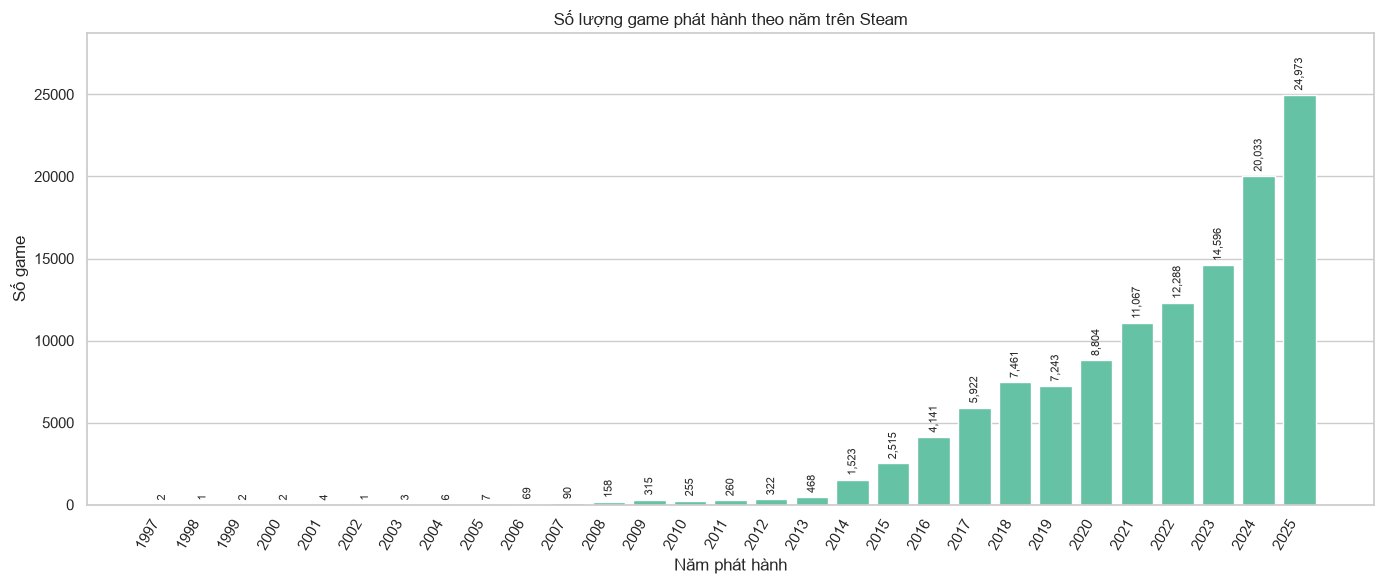

In [2]:
ngay = pd.to_datetime(df["Release date"], format="mixed", errors="coerce")
print("Số game không đọc được ngày phát hành:", ngay.isna().sum())

nam = ngay.dt.year.dropna().astype(int)
so_game = nam.value_counts().sort_index()
so_game = so_game[so_game.index <= 2025]          # bỏ năm 2026 (dữ liệu chưa đủ năm)

plt.figure(figsize=(14, 6))
ax = plt.gca()
ax.bar(so_game.index, so_game.values, color=sns.color_palette()[0], edgecolor="white")
ax.bar_label(ax.containers[0], labels=[f"{v:,}" for v in so_game.values], rotation=90, fontsize=8, padding=3)
ax.set_xticks(so_game.index)
ax.set_xticklabels(so_game.index, rotation=60, ha="right")
ax.set_ylim(0, so_game.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set(title="Số lượng game phát hành theo năm trên Steam",
       xlabel="Năm phát hành", ylabel="Số game")
plt.tight_layout()
plt.show()

Nhận xét:

-Số game phát hành mỗi năm tăng mạnh và gần như liên tục. Trước 2006, mỗi năm chỉ có 1–7 game. Từ 2014 số game bắt đầu tăng nhanh (1.523 game), đến 2025 đạt 24.973 game, gấp khoảng 3,3 lần năm 2018 và 2,8 lần năm 2020. Chỉ có một năm giảm nhẹ là 2019 (−2,9%), sau đó tăng trở lại. Xu hướng cho thấy thị trường game trên Steam mở rộng rất nhanh, nhất là trong những năm gần đây.

-Năm 2023 có 14.598 game, năm 2024 có 20.033 game, tức tăng thêm 5.435 game, tương ứng +37,2%. Đây là mức tăng phần trăm cao nhất kể từ 2017.

-Năm 2025 có 24.973 game, tăng thêm 4.940 game so với 2024, tương ứng +24,7%. Tốc độ tăng chậm lại so với năm trước (37,2% xuống 24,7%) nhưng số game tăng thêm vẫn rất lớn.


In [3]:
%pip install seaborn matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\ADMIN\env_2026\Scripts\python.exe -m pip install --upgrade pip


### Nhiệm vụ #34 – Phân tích tương quan (Correlation Analysis)

In [4]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

while PROJECT_ROOT.name in ("notebooks", "archive"):
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

print("Thư mục dự án:", PROJECT_ROOT)
print("Tìm thấy src:", (PROJECT_ROOT / "src").exists())

Thư mục dự án: D:\Games_Data_Science
Tìm thấy src: True


#### Đọc dữ liệu và kiểm tra các cột số

In [5]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd()

while PROJECT_ROOT.name in ("notebooks", "archive"):
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "games_cleaned.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Kích thước dữ liệu:", df.shape)
print("\nCác cột số:")
print(df.select_dtypes(include="number").columns.tolist())

Kích thước dữ liệu: (125846, 21)

Các cột số:
['id', 'Peak CCU', 'Price', 'Discount', 'DLC count', 'Positive', 'Negative', 'User score', 'Metacritic score', 'Recommendations', 'Achievements', 'Average playtime forever', 'Average playtime two weeks', 'Median playtime forever', 'Median playtime two weeks']


""" Chọn các biến để phân tích
Ban đầu, hãy thử với các biến sau:
Biến	Ý nghĩa
Price	Giá game
Positive	Số đánh giá tích cực
Negative	Số đánh giá tiêu cực
Peak CCU	Số người chơi đồng thời đạt đỉnh
Recommendations	Số lượt đề xuất
Metacritic score	Điểm đánh giá Metacritic

Tên và ý nghĩa các cột dựa trên bộ dữ liệu Steam Games bạn đang sử dụng. 
Cần xác nhận chúng có tồn tại và được đọc đúng kiểu dữ liệu trước khi phân tích."""

#### Tính ma trận tương quan

In [6]:
columns = [
    "Price",
    "Positive",
    "Negative",
    "Peak CCU",
    "Recommendations",
    "Metacritic score"
]

available_columns = [
    col for col in columns
    if col in df.columns
]

numeric_df = df[available_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

correlation_matrix = numeric_df.corr(method="pearson")

display(correlation_matrix.round(2))

,Price,Positive,Negative,Peak CCU,Recommendations,Metacritic score
Price,1.00,0.01,0.01,0.00,0.02,0.17
Positive,0.01,1.00,0.82,0.85,0.90,0.18
Negative,0.01,0.82,1.00,0.83,0.74,0.10
Peak CCU,0.00,0.85,0.83,1.00,0.66,0.06
Recommendations,0.02,0.90,0.74,0.66,1.00,0.19
Metacritic score,0.17,0.18,0.10,0.06,0.19,1.00


#### Vẽ heatmap

In [7]:
#Kiểm tra các hàm có trong plots.py(chạy vì bị lỗi không gọi được hàm để vẽ heatmap)
import importlib
import src.plots as plots

importlib.reload(plots)

print([name for name in dir(plots) if name.startswith("plot_")])

['plot_correlation_heatmap', 'plot_histogram', 'plot_positive_negative_reviews', 'plot_top_peak_ccu']


In [8]:
from pathlib import Path

print("Thư mục hiện tại:", Path.cwd())
print("Thư mục src tồn tại:", (Path.cwd().parent / "src").exists())

Thư mục hiện tại: D:\Games_Data_Science\notebooks\archive
Thư mục src tồn tại: False


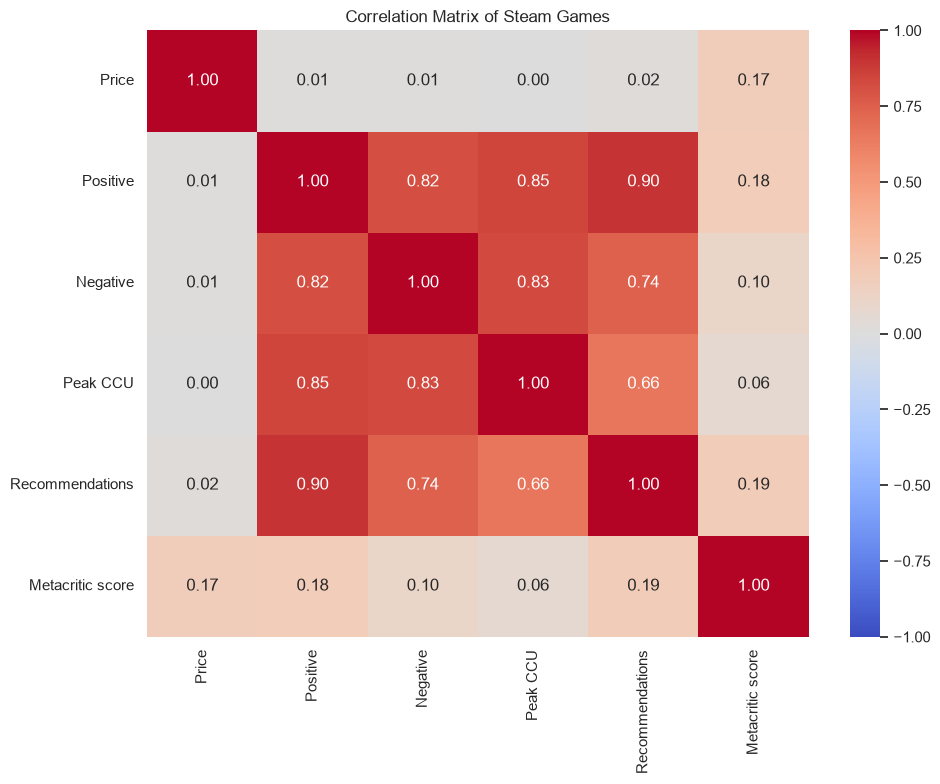

In [9]:
plots.plot_correlation_heatmap(correlation_matrix)

*Xong nhiệm vụ #34.*

In [10]:
# -------------------------------

### Nhiệm vụ #35 – Trực quan hóa dữ liệu rõ ràng

In [11]:
import importlib
import src.plots as plots

importlib.reload(plots)

<module 'src.plots' from 'D:\\Games_Data_Science\\src\\plots.py'>

#### Vẽ biểu đồ giá game bằng hàm plot_histogram

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Distribution of Game Prices'}, xlabel='Price', ylabel='Count'>)

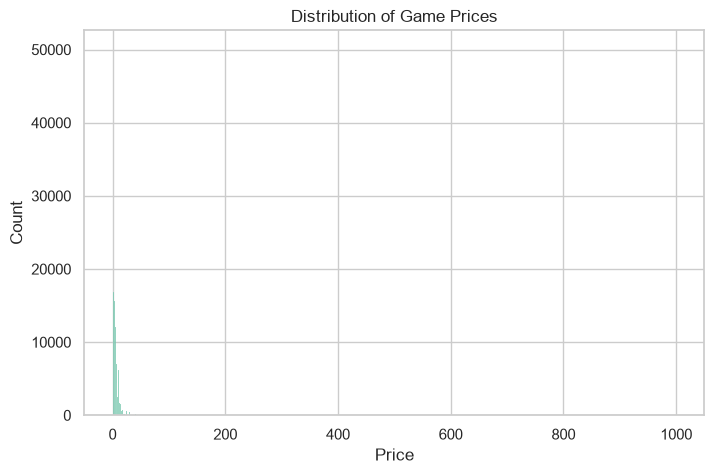

In [12]:
plots.plot_histogram(df["Price"], title="Distribution of Game Prices")

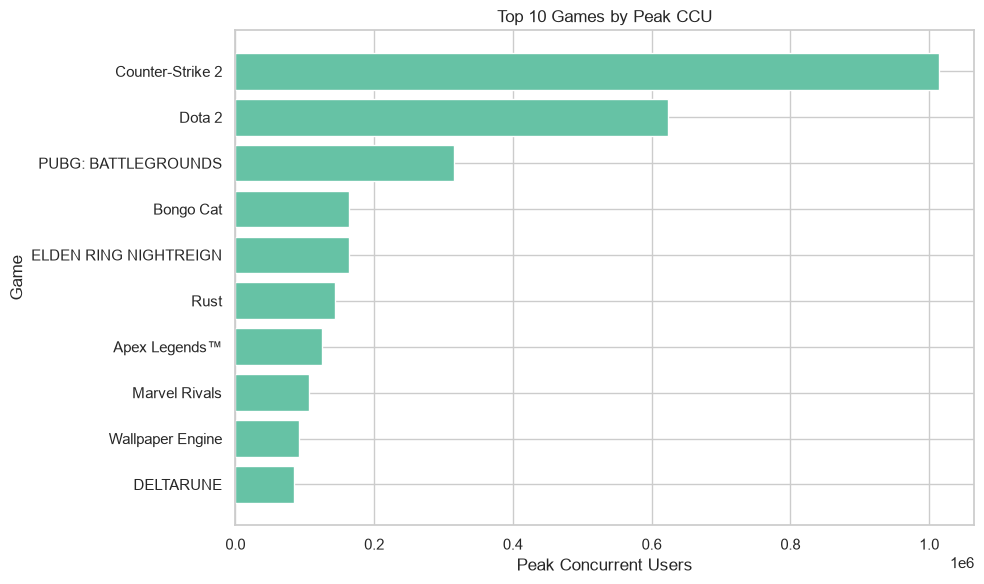

In [13]:
plots.plot_top_peak_ccu(df, top_n=10)

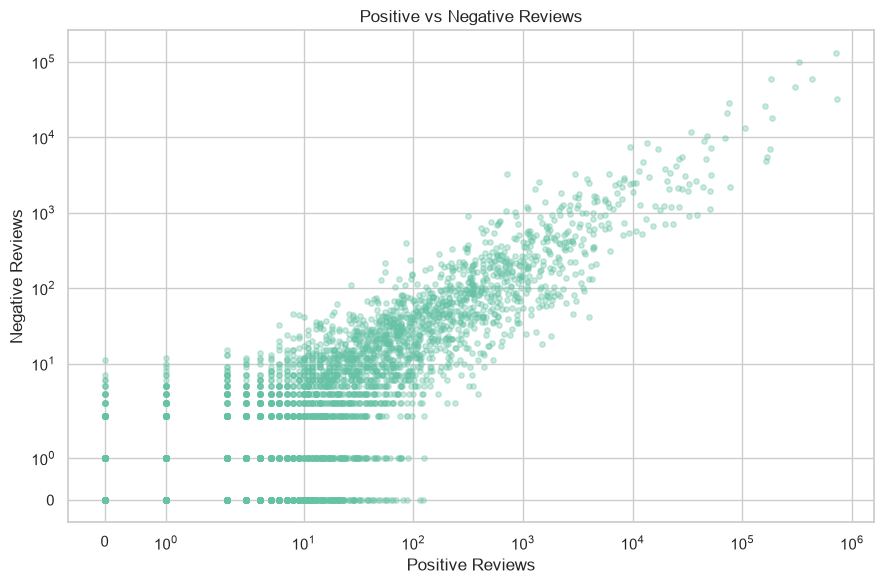

In [14]:
plots.plot_positive_negative_reviews(df)

*Xong nhiệm vụ #35.*

In [15]:
# -------------------------------

### Nhiệm vụ #36 – Phát hiện giả thuyết, xu hướng và điểm bất thường (Patterns, Hypotheses & Anomalies)

#### Kiểm tra giả thuyết về mức độ tập trung người chơi

In [16]:
#Tính tỷ trọng Peak CCU của Top 10 game

import pandas as pd

# Chuyen Peak CCU sang dang so
df["Peak CCU"] = pd.to_numeric(
    df["Peak CCU"], errors="coerce"
)

# Loai bo gia tri thieu va gia tri am
ccu = df.loc[df["Peak CCU"] >= 0, "Peak CCU"].dropna()

# Tinh tong Peak CCU cua tat ca game
total_ccu = ccu.sum()

# Tinh tong Peak CCU cua 10 game cao nhat
top10_ccu = ccu.nlargest(10).sum()

# In ket qua
print(f"So game hop le: {len(ccu):,}")
print(f"Tong Peak CCU: {total_ccu:,.0f}")
print(f"Top 10 Peak CCU: {top10_ccu:,.0f}")

if total_ccu > 0:
    ratio = top10_ccu / total_ccu
    print(f"Ty trong Top 10: {ratio:.2%}")


So game hop le: 125,846
Tong Peak CCU: 6,693,875
Top 10 Peak CCU: 2,830,189
Ty trong Top 10: 42.28%


In [17]:
"""- Chỉ 10 game trong tổng số 125.846 game đã chiếm khoảng 42,28% tổng các giá trị Peak CCU.
- Điều này cho thấy các giá trị người chơi đồng thời cao nhất tập trung đáng kể vào một nhóm nhỏ game.
- Đây là bằng chứng ủng hộ giả thuyết về sự tập trung của Peak CCU.
Lưu ý: Đây là tỷ trọng tổng các giá trị Peak CCU của từng game, không phải tỷ trọng người chơi duy nhất trên toàn Steam. Mỗi game có thể ghi nhận đỉnh người chơi vào thời điểm khác nhau."""

'- Chỉ 10 game trong tổng số 125.846 game đã chiếm khoảng 42,28% tổng các giá trị Peak CCU.\n- Điều này cho thấy các giá trị người chơi đồng thời cao nhất tập trung đáng kể vào một nhóm nhỏ game.\n- Đây là bằng chứng ủng hộ giả thuyết về sự tập trung của Peak CCU.\nLưu ý: Đây là tỷ trọng tổng các giá trị Peak CCU của từng game, không phải tỷ trọng người chơi duy nhất trên toàn Steam. Mỗi game có thể ghi nhận đỉnh người chơi vào thời điểm khác nhau.'

#### Kiểm tra xu hướng giá game

In [18]:
#Thống kê phân phối giá
"""Nếu giá trung bình lớn hơn trung vị đáng kể, một số giá cao có thể đang kéo trung bình lên.



Nếu tỷ lệ giá bằng 0 cao, game miễn phí là một nhóm đáng chú ý trong dữ liệu.



Giá cao nhất chưa chắc là dữ liệu sai; cần kiểm tra từng trường hợp trước khi kết luận."""

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

price = df.loc[df["Price"] >= 0, "Price"].dropna()

print("So game co gia hop le:", len(price))
print("Gia trung binh:", round(price.mean(), 2))
print("Gia trung vi:", round(price.median(), 2))
print("Gia 75%:", round(price.quantile(0.75), 2))
print("Gia cao nhat:", round(price.max(), 2))

print("\nTy le game mien phi:")
print(f"{(price == 0).mean():.2%}")


So game co gia hop le: 125846
Gia trung binh: 4.81
Gia trung vi: 2.39
Gia 75%: 5.52
Gia cao nhat: 999.98

Ty le game mien phi:
21.18%


In [19]:
"""Nhận xét:
- Giá trung bình 4,81 cao hơn đáng kể so với trung vị 2,39. Điều này phù hợp với dấu hiệu phân phối lệch phải: một số giá cao kéo mức trung bình lên.
- 75% game có giá không vượt quá 5,52, trong khi giá cao nhất là 999,98. Đây là một giá trị cực trị đáng kiểm tra.
- 21,18% game có giá bằng 0, cho thấy nhóm game miễn phí chiếm tỷ lệ đáng kể.
Giả thuyết: Phần lớn game có giá tương đối thấp, trong khi một nhóm nhỏ có giá cao hơn nhiều.
 Tuy nhiên, giá 999,98 chưa thể được xem là lỗi nếu chưa kiểm tra thông tin game tương ứng."""

'Nhận xét:\n- Giá trung bình 4,81 cao hơn đáng kể so với trung vị 2,39. Điều này phù hợp với dấu hiệu phân phối lệch phải: một số giá cao kéo mức trung bình lên.\n- 75% game có giá không vượt quá 5,52, trong khi giá cao nhất là 999,98. Đây là một giá trị cực trị đáng kiểm tra.\n- 21,18% game có giá bằng 0, cho thấy nhóm game miễn phí chiếm tỷ lệ đáng kể.\nGiả thuyết: Phần lớn game có giá tương đối thấp, trong khi một nhóm nhỏ có giá cao hơn nhiều.\n Tuy nhiên, giá 999,98 chưa thể được xem là lỗi nếu chưa kiểm tra thông tin game tương ứng.'

#### Kiểm tra những game có ít đánh giá

In [20]:
#Thống kê số lượt đánh giá
"""Biểu đồ Positive vs Negative Reviews cho thấy nhiều điểm nằm sát phía trái. 
Điều này có thể do nhiều game có số lượt đánh giá thấp.
 Ta cần kiểm tra bằng số liệu thay vì đoán."""


df["Positive"] = pd.to_numeric(df["Positive"], errors="coerce")
df["Negative"] = pd.to_numeric(df["Negative"], errors="coerce")

reviews = df[["Positive", "Negative"]].dropna()

reviews["Total Reviews"] = (
    reviews["Positive"] + reviews["Negative"]
)

print("Số game có dữ liệu đánh giá:", len(reviews))
print("Số game chưa có đánh giá:",
      (reviews["Total Reviews"] == 0).sum())
print("Số game có dưới 10 lượt đánh giá:",
      (reviews["Total Reviews"] < 10).sum())
print("Số game có trên 1.000 lượt đánh giá:",
      (reviews["Total Reviews"] > 1000).sum())


Số game có dữ liệu đánh giá: 125846
Số game chưa có đánh giá: 42890
Số game có dưới 10 lượt đánh giá: 69184
Số game có trên 1.000 lượt đánh giá: 7207


In [21]:
"""Nhận xét:
- Khoảng 34,08% game chưa có đánh giá nào.
- Khoảng 54,98% game có dưới 10 lượt đánh giá.
- Chỉ khoảng 5,73% game có trên 1.000 lượt đánh giá.
Điều này cho thấy số lượt đánh giá phân bố không đồng đều giữa các game.
 Nhiều game có rất ít đánh giá, trong khi một nhóm nhỏ nhận được nhiều đánh giá hơn đáng kể.

Đây cũng là lý do biểu đồ Positive vs Negative Reviews tập trung dày ở gần gốc tọa độ. 
Tuy nhiên, cần nhớ rằng số lượt đánh giá ít không đồng nghĩa với dữ liệu sai."""

'Nhận xét:\n- Khoảng 34,08% game chưa có đánh giá nào.\n- Khoảng 54,98% game có dưới 10 lượt đánh giá.\n- Chỉ khoảng 5,73% game có trên 1.000 lượt đánh giá.\nĐiều này cho thấy số lượt đánh giá phân bố không đồng đều giữa các game.\n Nhiều game có rất ít đánh giá, trong khi một nhóm nhỏ nhận được nhiều đánh giá hơn đáng kể.\n\nĐây cũng là lý do biểu đồ Positive vs Negative Reviews tập trung dày ở gần gốc tọa độ. \nTuy nhiên, cần nhớ rằng số lượt đánh giá ít không đồng nghĩa với dữ liệu sai.'

#### Tổng kết nhiệm vụ #36

**1. Mức độ tập trung Peak CCU**

Top 10 game có tổng Peak CCU là 2.830.189, chiếm 42,28% tổng Peak CCU của bộ dữ liệu. Kết quả cho thấy các giá trị Peak CCU tập trung đáng kể vào nhóm game dẫn đầu. Tuy nhiên, đây không phải tỷ trọng người chơi duy nhất trên toàn Steam.

**2. Xu hướng giá game**

Giá trung bình là 4,81, cao hơn trung vị 2,39. Phân vị 75% là 5,52, trong khi giá cao nhất đạt 999,98. Kết quả phù hợp với dấu hiệu phân phối giá lệch phải. Khoảng 21,18% game có giá bằng 0. Giá cao nhất cần được kiểm tra thêm trước khi kết luận là dữ liệu sai.

**3. Mức độ phổ biến của đánh giá**

Trong 125.846 game, có 42.890 game chưa có đánh giá và 69.184 game có dưới 10 lượt đánh giá. Chỉ 7.207 game có trên 1.000 lượt đánh giá. Điều này cho thấy số lượt đánh giá phân bố không đồng đều giữa các game.

**4. Điểm cần kiểm tra thêm**

- Xác minh game có giá 999,98.
- Kiểm tra các game có giá trị đánh giá bằng 0 để phân biệt game chưa có đánh giá với trường hợp dữ liệu thiếu hoặc sai.
- Tiếp tục xác minh các giá trị cực trị trước khi quyết định có cần làm sạch hay không.

**Kết luận:** Phân tích đã phát hiện các xu hướng về mức độ tập trung Peak CCU, phân phối giá và số lượt đánh giá. Những kết quả này hỗ trợ việc hình thành giả thuyết và xác định các trường hợp cần kiểm tra thêm, nhưng không tự chứng minh quan hệ nhân quả.
